# Weekend Bitcoin Prices and Monday Drift in Crypto-exposed Equities

**Question.** Does Bitcoin's return between Friday's 16:00 New York close and Monday 09:00 New York time
predict the Monday **open-to-close** return of an equal-weight basket of MSTR, MARA and RIOT?

**Two outcomes are kept separate throughout:**

| Outcome | Definition 
|---|---|
| Opening gap | Friday close → Monday open |
| Monday drift | Monday open → Monday close |

**Primary rule (registered before looking at returns):** if the Bitcoin return from Friday 16:00 to Monday 09:00 (NY)
is > 0, buy the basket at Monday's open and sell at Monday's close; otherwise hold cash.
Benchmark: buy the same basket every eligible Monday.

**Secondary analysis:** the same Bitcoin → gap / drift relationship on ordinary weeknights (16:00 → 09:00 next day),
to see whether the longer weekend closure leaves more unabsorbed information than a single night.


## 0. Setup and registered configuration

Everything that defines the experiment lives in `CONFIG` and is saved to `data/metadata/config.json`.

**What the out-of-sample lock did and did not do.** The cleaning stage builds the outcome table (gaps and drifts) for the *whole* 2021–2025 sample in one pass, so 2024–2025 outcomes were computed and saved to `data/processed/outcomes.csv` from the first run. What `OUT_OF_SAMPLE_UNLOCKED = False` withheld was every *use* of them: no 2024–2025 outcome, signal–outcome relationship, regression, strategy return or metric was displayed, analysed or evaluated until the design-freeze commit (`fec2b54`). All analysis cells before section 8 filter explicitly to `period == "in_sample"`.

In [1]:
import datetime as dt
import hashlib
import io
import json
import platform
import time
import zipfile
from bisect import bisect_right
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pandas_market_calendars as mcal
import requests
import scipy
import statsmodels
import statsmodels.api as sm
import yfinance as yf
from scipy import stats

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

NY = "America/New_York"
DATA = Path("data")
RAW_BTC = DATA / "raw" / "btc"
RAW_EQ = DATA / "raw" / "equity"
PROCESSED = DATA / "processed"
META = DATA / "metadata"
RESULTS = DATA / "results"
FIGURES = DATA / "figures"
for p in (RAW_BTC, RAW_EQ, PROCESSED, META, RESULTS, FIGURES):
    p.mkdir(parents=True, exist_ok=True)

# Set True only to deliberately re-download sources. Default runs entirely from the saved snapshot.
REFRESH = False

# Flipped to True only after the design-freeze entry in data/metadata/decision_log.md.
OUT_OF_SAMPLE_UNLOCKED = True

In [2]:
CONFIG = {
    "universe": ["MSTR", "MARA", "RIOT"],
    "weights": {"MSTR": 1 / 3, "MARA": 1 / 3, "RIOT": 1 / 3},
    "btc_source": {
        "exchange": "Binance spot public archive (data.binance.vision)",
        "pair": "BTCUSDT",
        "interval": "30m",
        "base_url": "https://data.binance.vision/data/spot/monthly/klines/BTCUSDT/30m/",
        "first_month": "2020-12",
        "last_month": "2025-12",
    },
    "equity_source": {
        "provider": "yfinance Ticker.history",
        "interval": "1d",
        "auto_adjust": False,
        "actions": True,
        "start": "2020-12-01",
        "end_exclusive": "2026-01-01",
    },
    "calendar": "NYSE via pandas_market_calendars (MSTR/MARA/RIOT are Nasdaq-listed; regular sessions coincide)",
    "sample": ["2021-01-01", "2025-12-31"],
    "periods": {
        "in_sample": ["2021-01-01", "2023-12-31"],
        "out_of_sample": ["2024-01-01", "2025-12-31"],
    },
    "signal_start": "16:00 NY on the prior full session (Friday for weekends)",
    "signal_cutoff_ny": "09:00",
    "entry_exit": "regular-session Open -> same-day regular-session Close",
    "threshold": 0.0,
    "sensitivity_thresholds": [0.01, 0.02],
    "base_cost_bps_per_side": 10,
    "cost_scenarios_bps": [0, 5, 10, 25, 50],
    "candle_close_tolerance_seconds": 1,
    "seed": 42,
    "bootstrap_reps": 2000,
    "cash_return": 0.0,
}
(META / "config.json").write_text(json.dumps(CONFIG, indent=2))

VERSIONS = {
    "python": platform.python_version(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "yfinance": yf.__version__,
    "pandas_market_calendars": mcal.__version__,
    "statsmodels": statsmodels.__version__,
    "scipy": scipy.__version__,
    "matplotlib": matplotlib.__version__,
}
VERSIONS

{'python': '3.12.14',
 'pandas': '3.0.6',
 'numpy': '2.5.3',
 'yfinance': '1.7.0',
 'pandas_market_calendars': '5.5.0',
 'statsmodels': '0.15.0',
 'scipy': '1.18.1',
 'matplotlib': '3.11.2'}

# 1. Data Acquisition

Three sources, each saved locally so the notebook reruns offline:

1. **Bitcoin** — Binance spot BTC/USDT 30-minute candles, one zip per month (Dec 2020 – Dec 2025).
   Each file is verified against Binance's published SHA-256 `.CHECKSUM` before it is accepted.
   BTC/USDT is a proxy for BTC/USD (stablecoin and single-venue risk acknowledged in the report).
2. **Equities** — yfinance daily OHLC for MSTR, MARA, RIOT with `auto_adjust=False, actions=True`,
   so splits/dividends are visible rather than silently applied.
3. **Session calendar** — NYSE regular sessions with exact open/close times (detects holidays and early closes).

In [3]:
def sha256_bytes(content):
    return hashlib.sha256(content).hexdigest()


def fetch(url, retries=3, timeout=30):
    # Bounded retries with linear back-off; re-raises after the last attempt.
    for attempt in range(1, retries + 1):
        try:
            response = requests.get(url, timeout=timeout)
            response.raise_for_status()
            return response.content
        except requests.RequestException:
            if attempt == retries:
                raise
            time.sleep(2 * attempt)


def load_previous_manifest():
    path = META / "manifest.json"
    return json.loads(path.read_text()) if path.exists() else {}


def download_or_load_btc_archive(config, refresh=False):
    src = config["btc_source"]
    months = pd.period_range(src["first_month"], src["last_month"], freq="M")
    previous = {r["file"]: r for r in load_previous_manifest().get("btc_files", [])}
    records = []
    for month in months:
        name = f"{src['pair']}-{src['interval']}-{month}.zip"
        path, checksum_path = RAW_BTC / name, RAW_BTC / f"{name}.CHECKSUM"
        downloaded_at = previous.get(name, {}).get("downloaded_at_utc")
        if refresh or not path.exists():
            content = fetch(src["base_url"] + name)
            checksum_text = fetch(src["base_url"] + name + ".CHECKSUM").decode()
            if path.exists() and sha256_bytes(path.read_bytes()) != sha256_bytes(content):
                raise RuntimeError(f"{name}: refreshed file differs from saved snapshot; not overwriting")
            path.write_bytes(content)
            checksum_path.write_text(checksum_text)
            downloaded_at = dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds")
        expected = checksum_path.read_text().split()[0]
        actual = sha256_bytes(path.read_bytes())
        if actual != expected:
            raise ValueError(f"{name}: SHA-256 mismatch with Binance CHECKSUM")
        records.append({"file": name, "month": str(month), "url": src["base_url"] + name,
                        "sha256": actual, "checksum_verified": True,
                        "bytes": path.stat().st_size, "downloaded_at_utc": downloaded_at})
    return pd.DataFrame(records)


t0 = time.perf_counter()
btc_files = download_or_load_btc_archive(CONFIG, refresh=REFRESH)
timing = {"btc_acquire_or_verify_s": time.perf_counter() - t0}
print(f"{len(btc_files)} monthly files, {btc_files.bytes.sum() / 1e6:.1f} MB, all checksums verified:",
      btc_files.checksum_verified.all())
btc_files.head(3)

61 monthly files, 5.1 MB, all checksums verified: True


,file,month,url,sha256,checksum_verified,bytes,downloaded_at_utc
0,BTCUSDT-30m-2020-12.zip,2020-12,https://data.binance.vision/data/spot/monthly/...,7ef1699a1d6396aece2041fafe99b22fcfa074dd2aadfa...,True,86766,2026-10-07T20:29:39+00:00
1,BTCUSDT-30m-2021-01.zip,2021-01,https://data.binance.vision/data/spot/monthly/...,cb7943bf16a16b73f2b70b8bc9f218dc59dbbd1716f6e6...,True,89719,2026-10-07T20:29:40+00:00
2,BTCUSDT-30m-2021-02.zip,2021-02,https://data.binance.vision/data/spot/monthly/...,194ab2b83edf84d80f47aaf98123130684ddd7aeed66cf...,True,80813,2026-10-07T20:29:42+00:00


In [4]:
def download_or_load_equities(config, refresh=False):
    src = config["equity_source"]
    previous = {r["ticker"]: r for r in load_previous_manifest().get("equity_files", [])}
    frames, records = {}, []
    for ticker in config["universe"]:
        path = RAW_EQ / f"{ticker}_daily.csv"
        downloaded_at = previous.get(ticker, {}).get("downloaded_at_utc")
        if refresh or not path.exists():
            hist = yf.Ticker(ticker).history(start=src["start"], end=src["end_exclusive"],
                                             interval=src["interval"], auto_adjust=src["auto_adjust"],
                                             actions=src["actions"])
            if hist.empty:
                raise RuntimeError(f"{ticker}: yfinance returned no rows")
            # The index is midnight New York time. Keep the *local* calendar date; converting the
            # instant to UTC first could shift a session onto the wrong date.
            hist.index = hist.index.tz_localize(None).normalize()
            hist.index.name = "date"
            hist.to_csv(path)
            downloaded_at = dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds")
        frames[ticker] = pd.read_csv(path, parse_dates=["date"]).set_index("date")
        records.append({"ticker": ticker, "file": str(path), "sha256": sha256_bytes(path.read_bytes()),
                        "rows": len(frames[ticker]), "request": src, "downloaded_at_utc": downloaded_at})
    return frames, pd.DataFrame(records)


t0 = time.perf_counter()
equity_raw, equity_files = download_or_load_equities(CONFIG, refresh=REFRESH)
timing["equity_acquire_or_load_s"] = time.perf_counter() - t0
equity_files[["ticker", "rows", "sha256", "downloaded_at_utc"]]

,ticker,rows,sha256,downloaded_at_utc
0,MSTR,1277,e78168c62a26def1cf396d6f5c74d9f038b4d17ffd46db...,2026-10-07T20:31:05+00:00
1,MARA,1277,9ccdce8aea765823722ad47e8f15ecfe37c4c04689612e...,2026-10-07T20:31:05+00:00
2,RIOT,1277,f1b4d2eac14e407a0cdce71f04750490dd7bb8f40f49fc...,2026-10-07T20:31:05+00:00


In [5]:
def build_session_calendar(start, end):
    sched = mcal.get_calendar("NYSE").schedule(start_date=start, end_date=end)
    cal = pd.DataFrame({
        "session": pd.DatetimeIndex(sched.index).normalize(),
        "open_utc": sched["market_open"].to_numpy(),
        "close_utc": sched["market_close"].to_numpy(),
    })
    cal["open_utc"] = pd.to_datetime(cal["open_utc"], utc=True)
    cal["close_utc"] = pd.to_datetime(cal["close_utc"], utc=True)
    cal["open_ny"] = cal["open_utc"].dt.tz_convert(NY)
    cal["close_ny"] = cal["close_utc"].dt.tz_convert(NY)
    cal["full_session"] = (cal["open_ny"].dt.strftime("%H:%M") == "09:30") & (
        cal["close_ny"].dt.strftime("%H:%M") == "16:00")
    return cal


calendar = build_session_calendar(CONFIG["equity_source"]["start"], "2025-12-31")
calendar.to_csv(META / "calendar_snapshot.csv", index=False)
print(len(calendar), "NYSE sessions;", (~calendar.full_session).sum(), "short sessions:")
calendar.loc[~calendar.full_session, ["session", "open_ny", "close_ny"]]

1277 NYSE sessions; 11 short sessions:


,session,open_ny,close_ny
17,2020-12-24,2020-12-24 09:30:00-05:00,2020-12-24 13:00:00-05:00
249,2021-11-26,2021-11-26 09:30:00-05:00,2021-11-26 13:00:00-05:00
500,2022-11-25,2022-11-25 09:30:00-05:00,2022-11-25 13:00:00-05:00
649,2023-07-03,2023-07-03 09:30:00-04:00,2023-07-03 13:00:00-04:00
750,2023-11-24,2023-11-24 09:30:00-05:00,2023-11-24 13:00:00-05:00
901,2024-07-03,2024-07-03 09:30:00-04:00,2024-07-03 13:00:00-04:00
1005,2024-11-29,2024-11-29 09:30:00-05:00,2024-11-29 13:00:00-05:00
1022,2024-12-24,2024-12-24 09:30:00-05:00,2024-12-24 13:00:00-05:00
1151,2025-07-03,2025-07-03 09:30:00-04:00,2025-07-03 13:00:00-04:00
1254,2025-11-28,2025-11-28 09:30:00-05:00,2025-11-28 13:00:00-05:00


In [6]:
manifest = {
    "created_or_verified_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"),
    "library_versions": VERSIONS,
    "btc_files": btc_files.to_dict("records"),
    "equity_files": equity_files.to_dict("records"),
    "calendar": {"provider": "pandas_market_calendars", "exchange": "NYSE",
                 "file": "data/metadata/calendar_snapshot.csv", "sessions": len(calendar)},
}
(META / "manifest.json").write_text(json.dumps(manifest, indent=2, default=str))
print("manifest written:", META / "manifest.json")

manifest written: data/metadata/manifest.json


# 2. Cleaning

### 2.1 Bitcoin candles

* Binance switched spot archive timestamps from **milliseconds to microseconds from January 2025**.
  The unit is chosen per file from its month, and every parsed timestamp must fall inside the month
  named in the filename — otherwise the run fails.
* A candle labelled 08:30 is only *known* once it finishes at 09:00. Each candle therefore gets a
  `candle_end = open_time + 30 min`, and prices are always looked up by the time the candle **ended**.
* Binance's `close_time` is normally `candle_end − 1 ms/µs`. A candle whose `close_time` is more than 1 s
  before `candle_end` was **truncated by an exchange outage/maintenance** — its close is not the price at
  `candle_end`. Such candles are kept, flagged `complete = False`, logged, and never used as an endpoint.
* Duplicates: identical rows are dropped and logged; conflicting duplicates stop the run.

In [7]:
KLINE_COLS = ["open_time", "open", "high", "low", "close", "volume", "close_time",
              "quote_volume", "n_trades", "taker_buy_base", "taker_buy_quote", "ignore"]
UNIT_SWITCH = pd.Period("2025-01", freq="M")


def parse_btc_file(path, month):
    with zipfile.ZipFile(path) as zf:
        raw = pd.read_csv(zf.open(zf.namelist()[0]), header=None, names=KLINE_COLS)
    if not pd.api.types.is_numeric_dtype(raw["open_time"]):  # tolerate a header row if one appears
        raw = raw[pd.to_numeric(raw["open_time"], errors="coerce").notna()].astype({"open_time": "int64"})
    unit = "us" if month >= UNIT_SWITCH else "ms"
    df = raw.copy()
    df["open_time"] = pd.to_datetime(df["open_time"].astype("int64"), unit=unit, utc=True)
    df["close_time"] = pd.to_datetime(df["close_time"].astype("int64"), unit=unit, utc=True)
    in_month = df["open_time"].dt.tz_convert(None).dt.to_period("M") == month
    if not in_month.all():
        raise ValueError(f"{path.name}: {(~in_month).sum()} timestamps outside {month} with unit={unit}")
    df["source_file"] = path.name
    return df


def clean_btc_candles(files, interval=pd.Timedelta("30min"), tolerance_s=1):
    issues = []
    frames = [parse_btc_file(RAW_BTC / f, pd.Period(m, freq="M")) for f, m in zip(files.file, files.month)]
    df = pd.concat(frames, ignore_index=True).sort_values("open_time", kind="mergesort")
    price_cols = ["open", "high", "low", "close"]

    dup_mask = df.duplicated("open_time", keep=False)
    if dup_mask.any():
        conflicting = df[dup_mask].groupby("open_time")[price_cols].nunique().gt(1).any(axis=1)
        if conflicting.any():
            raise ValueError(f"conflicting duplicate candles at {list(conflicting[conflicting].index)}")
        n_drop = int(df.duplicated("open_time").sum())
        issues.append({"dataset": "btc", "issue": "identical duplicate candles dropped", "count": n_drop})
        df = df.drop_duplicates("open_time")

    bad_ohlc = (df[price_cols] <= 0).any(axis=1) | (df["high"] < df[["open", "close"]].max(axis=1)) | (
        df["low"] > df[["open", "close"]].min(axis=1))
    if bad_ohlc.any():
        raise ValueError(f"{bad_ohlc.sum()} candles violate OHLC consistency")

    df["candle_end"] = df["open_time"] + interval
    close_gap = (df["candle_end"] - df["close_time"]).dt.total_seconds()
    if (close_gap < 0).any():
        raise ValueError("close_time after candle_end")
    df["complete"] = close_gap <= tolerance_s
    for _, r in df[~df["complete"]].iterrows():
        issues.append({"dataset": "btc", "issue": f"truncated candle {r.open_time:%Y-%m-%d %H:%M} UTC "
                       f"(close_time {r.close_time:%H:%M:%S}, volume {r.volume:g}) excluded from endpoints", "count": 1})

    grid = pd.date_range(df["open_time"].min(), df["open_time"].max(), freq=interval)
    missing = grid.difference(pd.DatetimeIndex(df["open_time"]))
    issues.append({"dataset": "btc", "issue": "missing 30m candles in archive (not filled)",
                   "count": len(missing)})
    return df.reset_index(drop=True), missing, issues


t0 = time.perf_counter()
btc, btc_missing, quality_log = clean_btc_candles(btc_files, tolerance_s=CONFIG["candle_close_tolerance_seconds"])
timing["btc_parse_clean_s"] = time.perf_counter() - t0
print(f"{len(btc):,} candles from {btc.open_time.min()} to {btc.open_time.max()}")
print(f"{len(btc_missing)} missing candle slots; grouped into outages:")
outages = pd.Series(btc_missing).groupby((pd.Series(btc_missing).diff() != pd.Timedelta("30min")).cumsum()).agg(["min", "max", "count"])
outages

89,094 candles from 2020-12-01 00:00:00+00:00 to 2025-12-31 23:30:00+00:00
42 missing candle slots; grouped into outages:


,min,max,count
1,2020-12-21 14:30:00+00:00,2020-12-21 17:30:00+00:00,7
2,2020-12-25 02:00:00+00:00,2020-12-25 02:30:00+00:00,2
3,2021-02-11 04:00:00+00:00,2021-02-11 04:30:00+00:00,2
4,2021-03-06 02:00:00+00:00,2021-03-06 03:00:00+00:00,3
5,2021-04-20 02:00:00+00:00,2021-04-20 04:00:00+00:00,5
6,2021-04-25 04:30:00+00:00,2021-04-25 08:00:00+00:00,8
7,2021-08-13 02:00:00+00:00,2021-08-13 06:00:00+00:00,9
8,2021-09-29 07:00:00+00:00,2021-09-29 08:30:00+00:00,4
9,2023-03-24 13:00:00+00:00,2023-03-24 13:30:00+00:00,2


### 2.2 Equities and corporate actions

yfinance with `auto_adjust=False` returns Open/High/Low/Close that are **already split-adjusted** (not raw
exchange prints) plus a separate `Adj Close` that additionally adjusts for cash dividends.
We verify rather than assume: (i) each ticker has exactly one row per NYSE session, (ii) no cash dividends
(so `Adj Close == Close`), (iii) the MSTR 10-for-1 split (effective 8 Aug 2024) leaves no artificial jump,
(iv) OHLC values are internally consistent. Nothing is forward-filled.

In [ ]:
def clean_equity_data(frames, calendar, issues):
    sessions = pd.DatetimeIndex(calendar["session"])
    clean = {}
    for ticker, df in frames.items():
        df = df.sort_index()
        if df.index.duplicated().any():
            raise ValueError(f"{ticker}: duplicate dates")
        missing = sessions.difference(df.index)
        extra = df.index.difference(sessions)
        issues.append({"dataset": ticker, "issue": "sessions missing vs calendar", "count": len(missing)})
        issues.append({"dataset": ticker, "issue": "rows on non-session dates", "count": len(extra)})
        if len(extra):
            raise ValueError(f"{ticker}: rows on non-session dates {list(extra)[:5]}")
        bad = (df[["Open", "High", "Low", "Close"]] <= 0).any(axis=1) | (
            df["High"] < df[["Open", "Close"]].max(axis=1)) | (df["Low"] > df[["Open", "Close"]].min(axis=1))
        if bad.any():
            raise ValueError(f"{ticker}: {int(bad.sum())} rows with non-positive or inconsistent OHLC prices")
        issues.append({"dataset": ticker, "issue": "OHLC inconsistent rows", "count": int(bad.sum())})
        n_div = int((df["Dividends"] != 0).sum())
        issues.append({"dataset": ticker, "issue": "cash dividend rows", "count": n_div})
        max_adj_gap = float((df["Adj Close"] / df["Close"] - 1).abs().max())
        issues.append({"dataset": ticker, "issue": "max |AdjClose/Close - 1|", "count": max_adj_gap})
        for d, ratio in df.loc[df["Stock Splits"] != 0, "Stock Splits"].items():
            issues.append({"dataset": ticker, "issue": f"stock split {ratio:g}:1 on {d.date()}", "count": 1})
        clean[ticker] = df[["Open", "High", "Low", "Close", "Adj Close", "Volume", "Dividends", "Stock Splits"]]
    return clean


equity = clean_equity_data(equity_raw, calendar, quality_log)
mstr = equity["MSTR"]
split_window = mstr.loc["2024-08-06":"2024-08-12", ["Open", "Close", "Stock Splits"]]
split_window["close_to_open_gap"] = split_window["Open"] / mstr["Close"].shift(1).loc[split_window.index] - 1
split_window

,Open,Close,Stock Splits,close_to_open_gap
date,,,,
2024-08-06,132.600006,136.921005,0.0,0.012987
2024-08-07,140.878006,124.684998,0.0,0.028900
2024-08-08,130.229996,135.990005,10.0,0.044472
2024-08-09,135.889999,135.369995,0.0,-0.000735
2024-08-12,133.490005,131.460007,0.0,-0.013888


In [9]:
quality = pd.DataFrame(quality_log)
quality.to_csv(META / "data_quality_log.csv", index=False)
quality

,dataset,issue,count
0,btc,truncated candle 2020-12-21 14:00 UTC (close_t...,1.0
1,btc,truncated candle 2021-02-11 03:30 UTC (close_t...,1.0
2,btc,truncated candle 2021-04-25 04:00 UTC (close_t...,1.0
3,btc,truncated candle 2021-12-24 04:30 UTC (close_t...,1.0
4,btc,truncated candle 2023-03-24 12:30 UTC (close_t...,1.0
5,btc,missing 30m candles in archive (not filled),42.0
6,MSTR,sessions missing vs calendar,0.0
7,MSTR,rows on non-session dates,0.0
8,MSTR,OHLC inconsistent rows,0.0
9,MSTR,cash dividend rows,0.0


### 2.3 Event table: pairing sessions and aligning completed Bitcoin candles

One row per **candidate** entry day in 2021–2025 (every calendar Monday for the weekend study, every
Tuesday–Friday for the weeknight study), including ineligible rows and the reason.

An event is eligible only if the entry day **and** the prior calendar trading day (Friday for Monday;
the previous day otherwise) are both **full** NYSE sessions, and both Bitcoin endpoint candles exist.
Tuesdays after a Monday holiday are *not* relabelled as Mondays.

**Endpoint lookup.** Candles are stored in a dictionary keyed by `candle_end`. The price at a target
time T is the close of the candle that ended **exactly** at T. If that candle is missing the event is
rejected — an older (stale) candle is never used and nothing is interpolated.

In [10]:
def build_close_lookup(candles):
    # O(B) build; O(1) average lookup per endpoint. Truncated (incomplete) candles are never endpoints.
    if "complete" in candles:
        candles = candles[candles["complete"]]
    return dict(zip(candles["candle_end"], candles["close"]))


def completed_price(lookup, target_utc):
    return lookup.get(target_utc, np.nan)


def ny_to_utc(date, hhmm):
    return (pd.Timestamp(date) + pd.Timedelta(hours=int(hhmm[:2]), minutes=int(hhmm[3:]))).tz_localize(NY).tz_convert("UTC")


def build_event_skeleton(calendar, start, end, cutoff_ny="09:00"):
    sess = calendar.set_index("session")
    days = pd.date_range(start, end, freq="D")
    rows = []
    for d in days[days.dayofweek < 5]:
        prior = d - pd.Timedelta(days=3 if d.dayofweek == 0 else 1)
        reason = None
        if d not in sess.index:
            reason = "entry day market closed"
        elif prior not in sess.index:
            reason = "prior day market closed"
        elif not sess.at[d, "full_session"]:
            reason = "entry day short session"
        elif not sess.at[prior, "full_session"]:
            reason = "prior day short session"
        rows.append({
            "event_id": d,
            "event_type": "weekend" if d.dayofweek == 0 else "weeknight",
            "prior_date": prior,
            "entry_date": d,
            "btc_start_target_utc": ny_to_utc(prior, "16:00"),
            "btc_cutoff_target_utc": ny_to_utc(d, cutoff_ny),
            "calendar_eligible": reason is None,
            "exclusion_reason": reason,
        })
    return pd.DataFrame(rows)


def build_signal_inputs(skeleton, lookup):
    # Only Bitcoin prices that finished at or before the cutoff are touched here.
    ev = skeleton.copy()
    ev["btc_start_price"] = [completed_price(lookup, t) for t in ev["btc_start_target_utc"]]
    ev["btc_cutoff_price"] = [completed_price(lookup, t) for t in ev["btc_cutoff_target_utc"]]
    btc_missing = ev["calendar_eligible"] & (ev["btc_start_price"].isna() | ev["btc_cutoff_price"].isna())
    ev.loc[btc_missing, "exclusion_reason"] = "btc endpoint candle missing"
    ev["eligible"] = ev["calendar_eligible"] & ~btc_missing
    ev["btc_return"] = np.where(ev["eligible"], ev["btc_cutoff_price"] / ev["btc_start_price"] - 1, np.nan)
    return ev


def assign_period(dates, periods):
    out = pd.Series("outside", index=dates.index)
    for name, (a, b) in periods.items():
        out[(dates >= a) & (dates <= b)] = name
    return out


t0 = time.perf_counter()
lookup = build_close_lookup(btc)
skeleton = build_event_skeleton(calendar, *CONFIG["sample"], cutoff_ny=CONFIG["signal_cutoff_ny"])
signal_inputs = build_signal_inputs(skeleton, lookup)
signal_inputs["period"] = assign_period(signal_inputs["entry_date"], CONFIG["periods"])
timing["event_alignment_s"] = time.perf_counter() - t0

reconciliation = (signal_inputs.assign(exclusion_reason=signal_inputs.exclusion_reason.fillna("eligible"))
                  .pivot_table(index=["event_type", "exclusion_reason"], columns="period",
                               values="event_id", aggfunc="count", fill_value=0))
reconciliation["total"] = reconciliation.sum(axis=1)
reconciliation

period                                  in_sample  out_of_sample  total
event_type exclusion_reason                                            
weekend    eligible                           128             91    219
           entry day market closed             19              9     28
           entry day short session              1              0      1
           prior day market closed              5              3      8
           prior day short session              3              2      5
weeknight  btc endpoint candle missing          1              0      1
           eligible                           592            384    976
           entry day market closed              9             12     21
           entry day short session              0              4      4
           prior day market closed             23             18     41

**Manual inspection of representative weekends.** Winter (EST, UTC−5), summer (EDT, UTC−4), the US
daylight-saving switch (14 Mar 2021) and holiday cases. The Friday 16:00 target must map to 21:00 UTC in
winter and 20:00 UTC in summer; Monday 09:00 to 14:00 / 13:00 UTC. Only the candidate rows and BTC
fields are shown (no equity outcomes).

In [11]:
inspect_dates = ["2021-01-11", "2021-03-15", "2021-07-12", "2021-11-08", "2021-01-18",
                 "2021-11-29", "2022-04-18", "2022-06-20", "2023-07-03"]
show = signal_inputs.set_index("event_id").loc[pd.to_datetime(inspect_dates),
    ["prior_date", "btc_start_target_utc", "btc_cutoff_target_utc", "btc_start_price",
     "btc_cutoff_price", "btc_return", "eligible", "exclusion_reason"]]
show

,prior_date,btc_start_target_utc,btc_cutoff_target_utc,btc_start_price,btc_cutoff_price,btc_return,eligible,exclusion_reason
2021-01-11,2021-01-08,2021-01-08 21:00:00+00:00,2021-01-11 14:00:00+00:00,39059.15,32813.71,-0.159897,True,NaN
2021-03-15,2021-03-12,2021-03-12 21:00:00+00:00,2021-03-15 13:00:00+00:00,56696.80,56439.53,-0.004538,True,NaN
2021-07-12,2021-07-09,2021-07-09 20:00:00+00:00,2021-07-12 13:00:00+00:00,33445.31,33566.19,0.003614,True,NaN
2021-11-08,2021-11-05,2021-11-05 20:00:00+00:00,2021-11-08 14:00:00+00:00,61090.69,65377.49,0.070171,True,NaN
2021-01-18,2021-01-15,2021-01-15 21:00:00+00:00,2021-01-18 14:00:00+00:00,35605.70,36766.78,NaN,False,entry day market closed
2021-11-29,2021-11-26,2021-11-26 21:00:00+00:00,2021-11-29 14:00:00+00:00,54515.70,57293.88,NaN,False,prior day short session
2022-04-18,2022-04-15,2022-04-15 20:00:00+00:00,2022-04-18 13:00:00+00:00,40313.35,39400.02,NaN,False,prior day market closed
2022-06-20,2022-06-17,2022-06-17 20:00:00+00:00,2022-06-20 13:00:00+00:00,20515.59,20555.68,NaN,False,entry day market closed
2023-07-03,2023-06-30,2023-06-30 20:00:00+00:00,2023-07-03 13:00:00+00:00,30372.36,30653.06,NaN,False,entry day short session


In [12]:
# Cross-check one weekend directly against the raw candle rows (the candle that *ends* at each target).
ev = signal_inputs.set_index("event_id").loc[pd.Timestamp("2021-03-15")]
raw_rows = btc[btc["candle_end"].isin([ev.btc_start_target_utc, ev.btc_cutoff_target_utc])]
raw_rows.assign(open_ny=raw_rows.open_time.dt.tz_convert(NY), end_ny=raw_rows.candle_end.dt.tz_convert(NY))[
    ["open_time", "candle_end", "open_ny", "end_ny", "close_time", "close", "source_file"]]

,open_time,candle_end,open_ny,end_ny,close_time,close,source_file
4875,2021-03-12 20:30:00+00:00,2021-03-12 21:00:00+00:00,2021-03-12 15:30:00-05:00,2021-03-12 16:00:00-05:00,2021-03-12 20:59:59.999000+00:00,56696.80,BTCUSDT-30m-2021-03.zip
5003,2021-03-15 12:30:00+00:00,2021-03-15 13:00:00+00:00,2021-03-15 08:30:00-04:00,2021-03-15 09:00:00-04:00,2021-03-15 12:59:59.999000+00:00,56439.53,BTCUSDT-30m-2021-03.zip


### 2.4 Outcomes (kept in a separate table from the predictor)

Per ticker: prior close, entry-day open and close. `gap = Open/prior Close − 1` (diagnostic, not tradable),
`drift = Close/Open − 1` (what the trade earns). Basket values are equal-weight means.
The hindsight-only Bitcoin return from 09:30 to 16:00 on the entry day is stored here too — it is an
explanatory diagnostic and is never passed to the signal.

In [13]:
def build_outcome_table(events, equity, lookup, universe):
    out = events[["event_id", "event_type", "period", "eligible", "prior_date", "entry_date"]].copy()
    for t in universe:
        px = equity[t]
        out[f"{t}_prior_close"] = out["prior_date"].map(px["Close"])
        out[f"{t}_open"] = out["entry_date"].map(px["Open"])
        out[f"{t}_close"] = out["entry_date"].map(px["Close"])
        out[f"{t}_gap"] = out[f"{t}_open"] / out[f"{t}_prior_close"] - 1
        out[f"{t}_drift"] = out[f"{t}_close"] / out[f"{t}_open"] - 1
    out["basket_gap"] = out[[f"{t}_gap" for t in universe]].mean(axis=1, skipna=False)
    out["basket_drift"] = out[[f"{t}_drift" for t in universe]].mean(axis=1, skipna=False)
    s930 = [completed_price(lookup, ny_to_utc(d, "09:30")) for d in out["entry_date"]]
    s1600 = [completed_price(lookup, ny_to_utc(d, "16:00")) for d in out["entry_date"]]
    out["btc_session_return_hindsight"] = np.array(s1600) / np.array(s930) - 1
    unresolved = out["eligible"] & out["basket_drift"].isna()
    out["unresolved_outcome"] = unresolved
    return out


outcomes = build_outcome_table(signal_inputs, equity, lookup, CONFIG["universe"])
print("eligible events with unresolved equity outcomes:", int(outcomes.unresolved_outcome.sum()))
assert not outcomes["unresolved_outcome"].any(), "unresolved post-entry valuation — fix before backtesting"

signal_inputs.to_csv(PROCESSED / "signal_inputs.csv", index=False)
outcomes.to_csv(PROCESSED / "outcomes.csv", index=False)

eligible events with unresolved equity outcomes: 0


# 3. Strategy

The signal function receives **only** predictor columns (event id, type, eligibility and the Bitcoin
return measured up to the 09:00 cutoff). It cannot see Monday prices. Registered rule: long the basket
on an eligible Monday when `btc_return > 0`. Sensitivities (+1%, +2%) are pre-declared and reported as
such, never substituted for the primary rule.

In [14]:
PREDICTOR_COLS = ["event_id", "event_type", "period", "eligible", "btc_return"]


def make_signal(signal_inputs, threshold=0.0, name="signal"):
    extra = set(signal_inputs.columns) - set(PREDICTOR_COLS)
    if extra:
        raise ValueError(f"signal function received non-predictor columns: {extra}")
    return (signal_inputs["eligible"] & (signal_inputs["btc_return"] > threshold)).rename(name)


predictors = signal_inputs[PREDICTOR_COLS]
signals = pd.DataFrame({
    "event_id": predictors["event_id"],
    "always": predictors["eligible"],  # unconditional benchmark: every eligible event
    "signal_long": make_signal(predictors, CONFIG["threshold"]),
    "signal_1pct": make_signal(predictors, CONFIG["sensitivity_thresholds"][0]),
    "signal_2pct": make_signal(predictors, CONFIG["sensitivity_thresholds"][1]),
})
signals.to_csv(PROCESSED / "signals.csv", index=False)

weekend_sig = signals[predictors["event_type"] == "weekend"].join(predictors["period"])
weekend_sig.groupby("period")[["always", "signal_long", "signal_1pct", "signal_2pct"]].sum()

,always,signal_long,signal_1pct,signal_2pct
period,,,,
in_sample,128,60,47,38
out_of_sample,91,53,37,29


# 4. Backtest

**Execution contract.** On a signal Monday, one-third of start-of-day wealth goes to each stock.
Each purchase pays an adverse proportional friction `c` at the Open, each sale pays `c` at the Close:

`net_return_i = (Close/Open)·(1 − c)/(1 + c) − 1`

No leverage, no shorts, no overnight holding; cash earns 0 and incurs no cost. Fractional shares
are allowed. The output is a **daily** return series over *every* NYSE session in the period
(zeros on cash days), compounded from wealth = 1, so Sharpe (√252, zero risk-free rate) and drawdown are
calendar-consistent. Gross (c = 0) and net results are both recorded.

In [ ]:
def asset_net_return(open_px, close_px, c):
    return (close_px / open_px) * (1 - c) / (1 + c) - 1


def run_portfolio(signal_col, period, cost_bps, event_type="weekend", config=CONFIG,
                  signals=signals, outcomes=outcomes, calendar=calendar):
    start, end = config["periods"][period] if isinstance(period, str) else period
    c = cost_bps / 1e4
    sessions = calendar.loc[calendar.session.between(start, end), "session"]
    merged = outcomes.merge(signals[["event_id", signal_col]], on="event_id")
    trades = merged[(merged.event_type == event_type) & merged[signal_col]
                    & merged.entry_date.between(start, end)].set_index("entry_date")
    daily = pd.Series(0.0, index=pd.DatetimeIndex(sessions, name="session"))
    ledger, wealth = [], 1.0
    for day in daily.index:
        if day not in trades.index:
            continue
        row, pnl_total = trades.loc[day], 0.0
        for t, w in config["weights"].items():
            o, cl = row[f"{t}_open"], row[f"{t}_close"]
            if not (np.isfinite(o) and np.isfinite(cl) and o > 0 and cl > 0):
                raise ValueError(f"{day.date()} {t}: missing or invalid execution price after entry decision")
            alloc = w * wealth
            shares = alloc / (o * (1 + c))
            proceeds = shares * cl * (1 - c)
            ledger.append({"date": day, "ticker": t, "wealth_before": wealth, "allocation": alloc,
                           "fill_open": o * (1 + c), "fill_close": cl * (1 - c), "shares": shares,
                           "proceeds": proceeds, "pnl": proceeds - alloc,
                           "gross_return": cl / o - 1, "net_return": proceeds / alloc - 1})
            pnl_total += proceeds - alloc
        daily[day] = pnl_total / wealth
        wealth += pnl_total
    return daily, pd.DataFrame(ledger)


def wealth_curve(daily):
    w = (1 + daily).cumprod()
    start = pd.Series([1.0], index=[w.index[0] - pd.Timedelta(days=1)])
    return pd.concat([start, w])  # includes initial wealth so an immediate loss shows in drawdown


def compute_metrics(daily, ledger):
    w = wealth_curve(daily)
    dd = w / w.cummax() - 1
    sd = daily.std(ddof=1)
    trade_days = ledger.groupby("date").apply(lambda g: g.pnl.sum() / g.wealth_before.iloc[0]) if len(ledger) else pd.Series(dtype=float)
    return {
        "sessions": len(daily),
        "trade_days": len(trade_days),
        "exposure": len(trade_days) / len(daily),
        "cumulative_return": w.iloc[-1] - 1,
        "sharpe_daily_zero_rf": np.sqrt(252) * daily.mean() / sd if sd > 0 else np.nan,
        "max_drawdown": dd.min(),
        "avg_trade_return": trade_days.mean() if len(trade_days) else np.nan,
        "median_trade_return": trade_days.median() if len(trade_days) else np.nan,
        "win_rate": (trade_days > 0).mean() if len(trade_days) else np.nan,
        "round_trip_turnover": (ledger.allocation.sum() + ledger.proceeds.sum()) / w.mean() if len(ledger) else 0.0,
    }

In [16]:
def results_table(periods, strategies, cost_bps):
    rows, ledgers, dailies = [], {}, {}
    for period in periods:
        for label, col in strategies.items():
            gross_daily, _ = run_portfolio(col, period, 0)
            daily, ledger = run_portfolio(col, period, cost_bps)
            m = compute_metrics(daily, ledger)
            m_gross = compute_metrics(gross_daily, ledger)
            rows.append({"period": period, "strategy": label,
                         "gross_cumulative_return": m_gross["cumulative_return"], **m})
            ledgers[(period, label)], dailies[(period, label)] = ledger, daily
    return pd.DataFrame(rows), ledgers, dailies


STRATEGIES = {"Positive BTC signal": "signal_long", "Unconditional Monday": "always"}
fmt = {"exposure": "{:.1%}", "cumulative_return": "{:.1%}", "gross_cumulative_return": "{:.1%}",
       "sharpe_daily_zero_rf": "{:.2f}", "max_drawdown": "{:.1%}", "avg_trade_return": "{:.2%}",
       "median_trade_return": "{:.2%}", "win_rate": "{:.1%}", "round_trip_turnover": "{:.1f}"}

is_table, is_ledgers, is_dailies = results_table(["in_sample"], STRATEGIES, CONFIG["base_cost_bps_per_side"])
is_table.style.format(fmt)

,period,strategy,gross_cumulative_return,sessions,trade_days,exposure,cumulative_return,sharpe_daily_zero_rf,max_drawdown,avg_trade_return,median_trade_return,win_rate,round_trip_turnover
0,in_sample,Positive BTC signal,-8.5%,753,60,8.0%,-18.8%,-0.16,-31.9%,-0.20%,-1.62%,40.0%,121.2
1,in_sample,Unconditional Monday,3.7%,753,128,17.0%,-19.7%,-0.05,-50.8%,-0.04%,-0.07%,48.4%,257.1


In [17]:
# Ledger reconciliation: wealth from compounding daily returns == wealth from summing ledger P&L.
for key, ledger in is_ledgers.items():
    daily = is_dailies[key]
    compounded = (1 + daily).prod()
    from_ledger = 1 + ledger.pnl.sum()
    assert np.isclose(compounded, from_ledger, rtol=1e-12), key
    assert (ledger.groupby("date").allocation.sum() <= ledger.groupby("date").wealth_before.first() + 1e-12).all()
print("ledgers reconcile to wealth; no day allocates more than 100% of wealth")
for key, ledger in is_ledgers.items():
    ledger.to_csv(RESULTS / f"ledger_{key[0]}_{'signal' if 'BTC' in key[1] else 'benchmark'}.csv", index=False)
is_ledgers[("in_sample", "Positive BTC signal")].head(6)

ledgers reconcile to wealth; no day allocates more than 100% of wealth


,date,ticker,wealth_before,allocation,fill_open,fill_close,shares,proceeds,pnl,gross_return,net_return
0,2021-01-25,MSTR,1.000000,0.333333,59.089029,57.084856,0.005641,0.322027,-0.011306,-0.031984,-0.033918
1,2021-01-25,MARA,1.000000,0.333333,19.519500,18.201779,0.017077,0.310831,-0.022503,-0.065641,-0.067508
2,2021-01-25,RIOT,1.000000,0.333333,22.032010,19.650330,0.015130,0.297300,-0.036034,-0.106315,-0.108101
3,2021-02-08,MSTR,0.930158,0.310053,92.675583,103.995898,0.003346,0.347925,0.037873,0.124396,0.122150
4,2021-02-08,MARA,0.930158,0.310053,26.966941,32.037930,0.011498,0.368356,0.058304,0.190423,0.188045
5,2021-02-08,RIOT,0.930158,0.310053,27.327299,32.757211,0.011346,0.371660,0.061607,0.201099,0.198699


### 4.3 Cost sensitivity (in-sample)

The 10 bps per side base cost is an assumption, not a measured spread. Both strategies are rerun at 0, 5, 10, 25 and 50 bps per side to show how much the conclusion depends on it. 0 bps equals the gross result.

In [18]:
cost_rows = []
for bps in CONFIG["cost_scenarios_bps"]:
    for label, col in STRATEGIES.items():
        daily, ledger = run_portfolio(col, "in_sample", bps)
        m = compute_metrics(daily, ledger)
        cost_rows.append({"cost_bps_per_side": bps, "strategy": label,
                          "cumulative_return": m["cumulative_return"],
                          "sharpe_daily_zero_rf": m["sharpe_daily_zero_rf"],
                          "max_drawdown": m["max_drawdown"],
                          "avg_trade_return": m["avg_trade_return"]})

cost_is = pd.DataFrame(cost_rows)
cost_is.to_csv(RESULTS / "cost_sensitivity_in_sample.csv", index=False)
cost_is.pivot(index="cost_bps_per_side", columns="strategy",
              values=["cumulative_return", "sharpe_daily_zero_rf"]).round(4)

cumulative_return                      sharpe_daily_zero_rf                     
strategy          Positive BTC signal Unconditional Monday  Positive BTC signal Unconditional Monday
cost_bps_per_side                                                                                   
0                             -0.0848               0.0367               0.0007               0.2049
5                             -0.1381              -0.0878              -0.0808               0.0795
10                            -0.1883              -0.1974              -0.1623              -0.0460
25                            -0.3220              -0.4533              -0.4060              -0.4227
50                            -0.4977              -0.7117              -0.8056              -1.0437

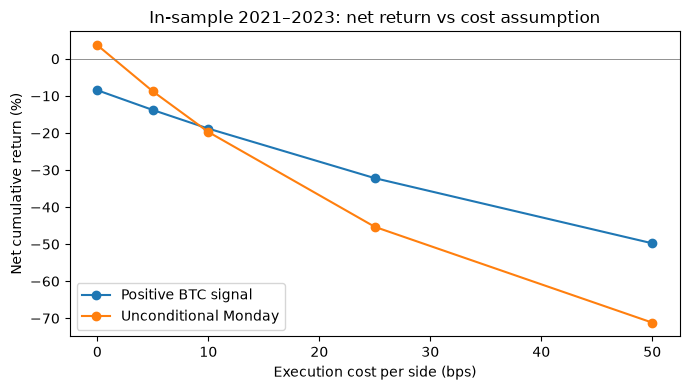

In [19]:
fig, ax = plt.subplots(figsize=(7, 4))
for label, g in cost_is.groupby("strategy"):
    ax.plot(g["cost_bps_per_side"], g["cumulative_return"] * 100, marker="o", label=label)
ax.axhline(0, color="grey", lw=0.6)
ax.set_xlabel("Execution cost per side (bps)")
ax.set_ylabel("Net cumulative return (%)")
ax.set_title("In-sample 2021–2023: net return vs cost assumption")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "is_cost_sensitivity.png", dpi=150)
plt.show()

### 4.4 Pre-declared threshold sensitivity (in-sample)

Thresholds of +1% and +2% were registered before any results were seen. They are reported for transparency only. The primary rule stays `BTC return > 0` regardless of which variant looks best.

In [20]:
SENSITIVITIES = {
    "Threshold > 0 (primary)": "signal_long",
    "Threshold > 1%": "signal_1pct",
    "Threshold > 2%": "signal_2pct",
    "Unconditional Monday": "always",
}
sens_is, _, _ = results_table(["in_sample"], SENSITIVITIES, CONFIG["base_cost_bps_per_side"])
sens_is.to_csv(RESULTS / "threshold_sensitivity_in_sample.csv", index=False)
sens_is[["strategy", "trade_days", "exposure", "gross_cumulative_return", "cumulative_return",
         "sharpe_daily_zero_rf", "max_drawdown", "avg_trade_return", "win_rate"]].style.format(fmt)

,strategy,trade_days,exposure,gross_cumulative_return,cumulative_return,sharpe_daily_zero_rf,max_drawdown,avg_trade_return,win_rate
0,Threshold > 0 (primary),60,8.0%,-8.5%,-18.8%,-0.16,-31.9%,-0.20%,40.0%
1,Threshold > 1%,47,6.2%,13.3%,3.2%,0.16,-26.7%,0.23%,42.6%
2,Threshold > 2%,38,5.0%,23.2%,14.2%,0.32,-18.9%,0.51%,42.1%
3,Unconditional Monday,128,17.0%,3.7%,-19.7%,-0.05,-50.8%,-0.04%,48.4%


## 5. Correctness checks

Small deterministic checks aimed at the errors that would actually invalidate the study
(timing, look-ahead, costs, valuation, metrics). Each is an `assert`; the notebook stops if one fails.

In [21]:
t_checks = time.perf_counter()
checks = []

# 1. A candle that STARTS at 09:00 must not be used for a 09:00 cutoff.
day = pd.Timestamp("2021-01-11")
c0830 = ny_to_utc(day, "08:30"); c0900 = ny_to_utc(day, "09:00"); c0930 = ny_to_utc(day, "09:30")
synthetic = pd.DataFrame({"open_time": [c0830, c0900], "close": [100.0, 999.0]})
synthetic["candle_end"] = synthetic["open_time"] + pd.Timedelta("30min")
lk = build_close_lookup(synthetic)
assert completed_price(lk, c0900) == 100.0 and completed_price(lk, c0930) == 999.0
checks.append("09:00 cutoff uses the 08:30-09:00 candle, never the 09:00-09:30 candle")

# 2. Winter / summer / DST-switch weekends map to the right UTC instants.
si = signal_inputs.set_index("event_id")
for monday, fri_utc, mon_utc in [("2021-01-11", "2021-01-08 21:00", "2021-01-11 14:00"),
                                 ("2021-03-15", "2021-03-12 21:00", "2021-03-15 13:00"),
                                 ("2021-07-12", "2021-07-09 20:00", "2021-07-12 13:00")]:
    assert si.at[pd.Timestamp(monday), "btc_start_target_utc"] == pd.Timestamp(fri_utc, tz="UTC")
    assert si.at[pd.Timestamp(monday), "btc_cutoff_target_utc"] == pd.Timestamp(mon_utc, tz="UTC")
checks.append("EST/EDT and the March-2021 DST switch map to correct UTC endpoints")

# 3. Holiday Monday, Good Friday weekend, short Friday, Juneteenth and short Monday never trade.
for d in ["2021-01-18", "2022-04-18", "2021-11-29", "2022-06-20", "2023-07-03"]:
    assert not si.at[pd.Timestamp(d), "eligible"]
    assert not signals.set_index("event_id").at[pd.Timestamp(d), "signal_long"]
checks.append("holiday / short-session weekends are excluded and generate no trade")

# 4. A missing endpoint candle is rejected, not replaced by a stale one.
lk_missing = dict(lookup); target = si.at[pd.Timestamp("2021-01-11"), "btc_cutoff_target_utc"]
del lk_missing[target]
test = build_signal_inputs(skeleton[skeleton.event_id == pd.Timestamp("2021-01-11")], lk_missing)
assert not test.eligible.iloc[0] and test.exclusion_reason.iloc[0] == "btc endpoint candle missing"
checks.append("missing endpoint candle -> event rejected (no stale fallback)")

# 5. Gap is not credited: $100 Fri close, $106 Mon open, $107 Mon close earns 107/106 - 1 gross.
assert np.isclose(asset_net_return(106.0, 107.0, 0.0), 107 / 106 - 1)
checks.append("$100/$106/$107 example earns 0.94%, not 7%")

# 6. Costs: flat price with zero friction = 0; positive friction is negative; cash days cost nothing.
assert asset_net_return(50.0, 50.0, 0.0) == 0.0 and asset_net_return(50.0, 50.0, 0.001) < 0
d10, l10 = run_portfolio("signal_long", "in_sample", 10)
assert (d10[~d10.index.isin(l10.date)] == 0).all()
checks.append("zero-friction flat trade = 0; friction > 0 is negative; no-trade days incur no cost")

# 7. Look-ahead: recompute every eligible signal from a view of the candles that ends at that event's
#    09:00 cutoff (later candles are invisible). Returns and signals must equal the pipeline's exactly.
class TruncatedCandles:
    """Read-only view of the sorted, complete candles that behaves as if nothing after `cutoff` exists."""

    def __init__(self, ends, closes, cutoff):
        self.ends, self.closes = ends, closes
        self.hi = bisect_right(ends, cutoff)  # visible candles are ends[0:hi]; no slice is created

    def get(self, target, default=np.nan):
        # Binary search bounded by hi: O(log B), no copying. Exact match only, so no stale fallback.
        i = bisect_right(self.ends, target, 0, self.hi) - 1
        return self.closes[i] if i >= 0 and self.ends[i] == target else default


# One-off preprocessing, O(B): complete candles only, already sorted by the cleaning step (O(B log B)).
t_prep = time.perf_counter()
complete_candles = btc[btc["complete"]]
ends_c, closes_c = complete_candles["candle_end"].tolist(), complete_candles["close"].tolist()
timing["truncated_view_prep_s"] = time.perf_counter() - t_prep
assert all(a < b for a, b in zip(ends_c, ends_c[1:]))  # binary search requires strictly sorted keys

# The view shows the candle ending at the cutoff, hides the next one...
cut = ny_to_utc("2021-01-11", "09:00")
probe = TruncatedCandles(ends_c, closes_c, cut)
assert probe.get(cut) == lookup[cut]
assert np.isnan(probe.get(ny_to_utc("2021-01-11", "09:30")))
# ...and never exposes the outage-truncated candle ending 2023-03-24 09:00 NY (nor does the pipeline's dict).
outage_end = ny_to_utc("2023-03-24", "09:00")
assert np.isnan(TruncatedCandles(ends_c, closes_c, outage_end).get(outage_end))
assert np.isnan(completed_price(lookup, outage_end))

cutoffs = signal_inputs.loc[signal_inputs.eligible,
                            ["event_id", "btc_start_target_utc", "btc_cutoff_target_utc", "btc_return"]]
rebuilt = []
for r in cutoffs.itertuples():
    view = TruncatedCandles(ends_c, closes_c, r.btc_cutoff_target_utc)
    rebuilt.append(completed_price(view, r.btc_cutoff_target_utc) / completed_price(view, r.btc_start_target_utc) - 1)
rebuilt = np.array(rebuilt)
assert np.array_equal(rebuilt, cutoffs["btc_return"].to_numpy())  # exactly identical returns

pipeline_signal = signals.set_index("event_id").loc[cutoffs["event_id"], "signal_long"].to_numpy()
assert np.array_equal(rebuilt > CONFIG["threshold"], pipeline_signal)  # identical trade decisions
checks.append(f"signal identical when all data after the 09:00 cutoff is hidden (all {len(cutoffs)} eligible events)")

# 8. Signal function refuses outcome columns.
try:
    make_signal(signal_inputs.merge(outcomes[["event_id", "basket_drift"]], on="event_id"))
    raise AssertionError("signal accepted outcome data")
except ValueError:
    checks.append("signal construction rejects any non-predictor (outcome) column")

# 9. Split: MSTR's 10:1 split day shows no artificial -90% gap.
assert abs(split_window.loc["2024-08-08", "close_to_open_gap"]) < 0.25
checks.append("MSTR 10:1 split (2024-08-08) produces no artificial gap in split-adjusted prices")

# 10. Metrics: an immediate loss shows in max drawdown; constant cash gives undefined Sharpe.
idx = pd.bdate_range("2021-01-04", periods=5)
m = compute_metrics(pd.Series([-0.1, 0, 0, 0, 0.0], index=idx), pd.DataFrame(columns=["date", "pnl", "wealth_before", "allocation", "proceeds"]))
assert np.isclose(m["max_drawdown"], -0.1)
m0 = compute_metrics(pd.Series(0.0, index=idx), pd.DataFrame(columns=["date", "pnl", "wealth_before", "allocation", "proceeds"]))
assert np.isnan(m0["sharpe_daily_zero_rf"])
checks.append("first-day loss appears in max drawdown; all-cash series gives Sharpe = N/A")

timing["correctness_checks_s"] = time.perf_counter() - t_checks
pd.Series(checks, name="passed check").to_frame()

,passed check
0,"09:00 cutoff uses the 08:30-09:00 candle, neve..."
1,EST/EDT and the March-2021 DST switch map to c...
2,holiday / short-session weekends are excluded ...
3,missing endpoint candle -> event rejected (no ...
4,"$100/$106/$107 example earns 0.94%, not 7%"
5,zero-friction flat trade = 0; friction > 0 is ...
6,signal identical when all data after the 09:00...
7,signal construction rejects any non-predictor ...
8,MSTR 10:1 split (2024-08-08) produces no artif...
9,first-day loss appears in max drawdown; all-ca...


## 6. In-sample explanatory analysis (2021–2023)

One observation per event (the equal-weight basket), so correlated stocks on the same day are not
counted as independent. Regressions are descriptive with heteroskedasticity-robust (HC3) standard errors.

In [22]:
def analysis_frame(period, event_type):
    df = predictors.merge(outcomes[["event_id", "basket_gap", "basket_drift", "btc_session_return_hindsight"]],
                          on="event_id")
    return df[(df.period == period) & (df.event_type == event_type) & df.eligible].dropna(subset=["basket_drift"])


def ols(df, y, xcols):
    X = sm.add_constant(df[xcols])
    fit = sm.OLS(df[y], X).fit(cov_type="HC3")
    out = pd.DataFrame({"coef": fit.params, "se_hc3": fit.bse, "p": fit.pvalues})
    out["n"], out["r2"] = int(fit.nobs), fit.rsquared
    return out


def conditional_drift(df, threshold=0.0):
    pos, neg = df.loc[df.btc_return > threshold, "basket_drift"], df.loc[df.btc_return <= threshold, "basket_drift"]
    t = stats.ttest_ind(pos, neg, equal_var=False)
    return pd.Series({"n_pos": len(pos), "mean_drift_pos": pos.mean(), "median_drift_pos": pos.median(),
                      "n_nonpos": len(neg), "mean_drift_nonpos": neg.mean(), "median_drift_nonpos": neg.median(),
                      "difference": pos.mean() - neg.mean(), "welch_t": t.statistic, "welch_p": t.pvalue})


is_wk = analysis_frame("in_sample", "weekend")
is_wn = analysis_frame("in_sample", "weeknight")
reg_is = pd.concat({
    ("weekend", "gap ~ btc"): ols(is_wk, "basket_gap", ["btc_return"]),
    ("weekend", "drift ~ btc"): ols(is_wk, "basket_drift", ["btc_return"]),
    ("weeknight", "gap ~ btc"): ols(is_wn, "basket_gap", ["btc_return"]),
    ("weeknight", "drift ~ btc"): ols(is_wn, "basket_drift", ["btc_return"]),
})
reg_is

coef    se_hc3              p    n        r2
weekend   gap ~ btc   const      -0.000422  0.001707   8.046542e-01  128  0.868698
                      btc_return  0.990882  0.054727   2.862227e-73  128  0.868698
          drift ~ btc const       0.001609  0.004746   7.345321e-01  128  0.000624
                      btc_return  0.026516  0.157181   8.660356e-01  128  0.000624
weeknight gap ~ btc   const       0.000737  0.000743   3.216595e-01  592  0.755067
                      btc_return  1.081274  0.040446  1.907543e-157  592  0.755067
          drift ~ btc const       0.000513  0.002216   8.169634e-01  592  0.000666
                      btc_return -0.047576  0.095871   6.197207e-01  592  0.000666

In [23]:
pd.DataFrame({"weekend": conditional_drift(is_wk), "weeknight": conditional_drift(is_wn)})

,weekend,weeknight
n_pos,60.000000,311.000000
mean_drift_pos,0.000009,0.001204
median_drift_pos,-0.014216,-0.000186
n_nonpos,68.000000,281.000000
mean_drift_nonpos,0.003070,-0.000385
median_drift_nonpos,0.004565,-0.006504
difference,-0.003061,0.001589
welch_t,-0.326620,0.361311
welch_p,0.744526,0.717996


In [24]:
def bootstrap_event_stats(df, cost_bps, reps, seed):
    # Resamples whole events (all three stocks together) with replacement; percentile 95% intervals.
    rng = np.random.default_rng(seed)
    c = cost_bps / 1e4
    x = df["btc_return"].to_numpy()
    drift = df["basket_drift"].to_numpy()
    pos = x > 0
    net = (1 + drift) * (1 - c) / (1 + c) - 1      # equal-weight basket net of costs (section 4 formula)
    excess = np.where(pos, net, 0.0) - net         # strategy minus benchmark on each event

    def stats_for(idx):
        p = pos[idx]
        return drift[idx][p].mean() - drift[idx][~p].mean(), excess[idx].mean()

    point = stats_for(np.arange(len(df)))
    draws = np.array([stats_for(rng.integers(0, len(df), len(df))) for _ in range(reps)])
    lo, hi = np.nanpercentile(draws, [2.5, 97.5], axis=0)
    return pd.DataFrame({"n_events": len(df), "estimate": point, "ci_2.5%": lo, "ci_97.5%": hi,
                         "share_of_draws_above_0": (draws > 0).mean(axis=0)},
                        index=["drift difference (BTC>0 minus BTC<=0)",
                               "excess return per event (strategy - benchmark, net)"])


boot_is_wk = bootstrap_event_stats(is_wk, CONFIG["base_cost_bps_per_side"], CONFIG["bootstrap_reps"], CONFIG["seed"])
boot_is_wn = bootstrap_event_stats(is_wn, CONFIG["base_cost_bps_per_side"], CONFIG["bootstrap_reps"], CONFIG["seed"]).iloc[:1]
boot_is = pd.concat({"weekend": boot_is_wk, "weeknight": boot_is_wn})
boot_is.to_csv(RESULTS / "bootstrap_in_sample.csv")
boot_is.round(4)

n_events  estimate  ci_2.5%  ci_97.5%  share_of_draws_above_0
weekend   drift difference (BTC>0 minus BTC<=0)                    128   -0.0031  -0.0220    0.0159                   0.372
          excess return per event (strategy - benchmark, ...       128   -0.0006  -0.0068    0.0055                   0.426
weeknight drift difference (BTC>0 minus BTC<=0)                    592    0.0016  -0.0072    0.0099                   0.649

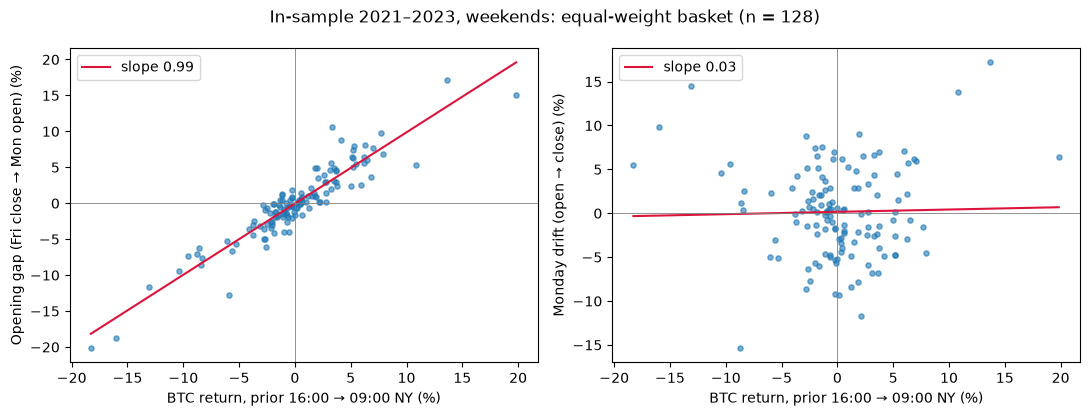

In [25]:
def scatter_panel(df, title, path):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True)
    for ax, y, label in [(axes[0], "basket_gap", "Opening gap (Fri close → Mon open)"),
                         (axes[1], "basket_drift", "Monday drift (open → close)")]:
        ax.scatter(df.btc_return * 100, df[y] * 100, s=14, alpha=0.6)
        b = np.polyfit(df.btc_return, df[y], 1)
        xs = np.linspace(df.btc_return.min(), df.btc_return.max(), 50)
        ax.plot(xs * 100, np.polyval(b, xs) * 100, color="crimson", lw=1.5, label=f"slope {b[0]:.2f}")
        ax.axhline(0, color="grey", lw=0.6); ax.axvline(0, color="grey", lw=0.6)
        ax.set_xlabel("BTC return, prior 16:00 → 09:00 NY (%)"); ax.set_ylabel(f"{label} (%)")
        ax.legend(loc="upper left")
    fig.suptitle(f"{title} (n = {len(df)})")
    fig.tight_layout(); fig.savefig(path, dpi=150); plt.show()


scatter_panel(is_wk, "In-sample 2021–2023, weekends: equal-weight basket", FIGURES / "is_weekend_scatter.png")

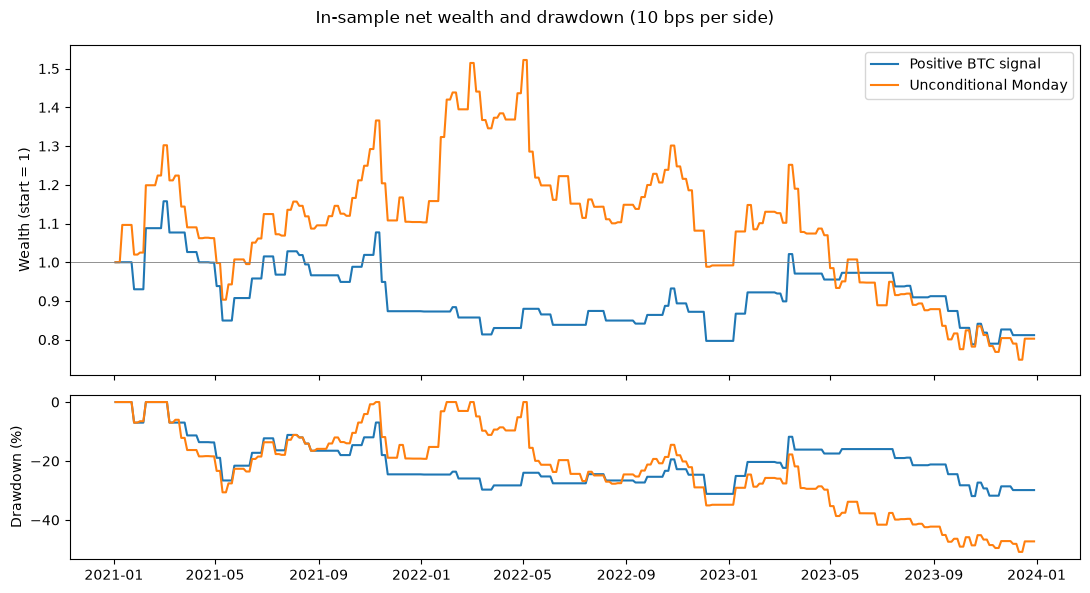

In [26]:
def wealth_drawdown_plot(dailies, title, path):
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
    for label, daily in dailies.items():
        w = wealth_curve(daily)
        a1.plot(w.index, w.values, label=label)
        a2.plot(w.index, (w / w.cummax() - 1).values * 100, label=label)
    a1.set_ylabel("Wealth (start = 1)"); a1.axhline(1, color="grey", lw=0.6); a1.legend()
    a2.set_ylabel("Drawdown (%)")
    fig.suptitle(title); fig.tight_layout(); fig.savefig(path, dpi=150); plt.show()


wealth_drawdown_plot({k[1]: v for k, v in is_dailies.items()},
                     f"In-sample net wealth and drawdown ({CONFIG['base_cost_bps_per_side']} bps per side)",
                     FIGURES / "is_wealth_drawdown.png")

### 6.1 Per-year breakdown (in-sample)

Checks whether one year dominates the in-sample average or whether the sign flips between years.

In [27]:
year_rows = []
for y in (2021, 2022, 2023):
    for label, col in STRATEGIES.items():
        daily, ledger = run_portfolio(col, (f"{y}-01-01", f"{y}-12-31"), CONFIG["base_cost_bps_per_side"])
        year_rows.append({"year": y, "strategy": label, **compute_metrics(daily, ledger)})
per_year_is = pd.DataFrame(year_rows)
per_year_is.to_csv(RESULTS / "per_year_in_sample.csv", index=False)

per_year_cond = (is_wk.assign(year=is_wk["event_id"].dt.year)
                 .groupby("year")[["btc_return", "basket_drift"]].apply(conditional_drift))
display(per_year_is[["year", "strategy", "trade_days", "cumulative_return", "sharpe_daily_zero_rf",
                     "max_drawdown", "win_rate"]].style.format(fmt))
per_year_cond[["n_pos", "mean_drift_pos", "n_nonpos", "mean_drift_nonpos", "difference", "welch_p"]].round(4)

,year,strategy,trade_days,cumulative_return,sharpe_daily_zero_rf,max_drawdown,win_rate
0,2021,Positive BTC signal,23,-12.6%,-0.26,-26.6%,39.1%
1,2021,Unconditional Monday,43,10.4%,0.45,-30.6%,53.5%
2,2022,Positive BTC signal,17,-8.8%,-0.50,-14.5%,41.2%
3,2022,Unconditional Monday,43,-10.1%,-0.15,-35.1%,48.8%
4,2023,Positive BTC signal,20,1.9%,0.19,-22.8%,40.0%
5,2023,Unconditional Monday,42,-19.1%,-0.50,-40.2%,42.9%


,n_pos,mean_drift_pos,n_nonpos,mean_drift_nonpos,difference,welch_p
year,,,,,,
2021,23.0,-0.0017,20.0,0.0144,-0.0160,0.3332
2022,17.0,-0.0027,26.0,0.0031,-0.0058,0.7035
2023,20.0,0.0042,22.0,-0.0073,0.0114,0.4717


### 6.2 Monday-session Bitcoin diagnostic (hindsight only, never a signal)

Adds Bitcoin's own 09:30 → 16:00 NY return on the entry day to the drift regression. This is known only after the trade, so it is purely explanatory: it tests whether Monday equity moves reflect same-day Bitcoin moves rather than delayed reaction to the weekend.

In [28]:
diag = is_wk.dropna(subset=["btc_session_return_hindsight"])
reg_diag = pd.concat({
    "drift ~ btc_overnight": ols(diag, "basket_drift", ["btc_return"]),
    "drift ~ btc_overnight + btc_session (hindsight)": ols(diag, "basket_drift",
                                                          ["btc_return", "btc_session_return_hindsight"]),
})
reg_diag.round(4)

coef  se_hc3       p    n      r2
drift ~ btc_overnight                           const                         0.0016  0.0047  0.7345  128  0.0006
                                                btc_return                    0.0265  0.1572  0.8660  128  0.0006
drift ~ btc_overnight + btc_session (hindsight) const                         0.0037  0.0035  0.2866  128  0.4727
                                                btc_return                    0.0300  0.1117  0.7879  128  0.4727
                                                btc_session_return_hindsight  1.5545  0.1407  0.0000  128  0.4727

### 6.3 Concentration (in-sample)

Cumulative net return with the 5 best or 5 worst trading days removed. A result that flips sign without a handful of days is fragile.

In [29]:
def concentration(daily, k=5):
    trades = daily[daily != 0]
    best, worst = trades.nlargest(k), trades.nsmallest(k)
    return pd.Series({
        "trade_days": len(trades),
        "cumulative_return": (1 + daily).prod() - 1,
        f"without_best_{k}": (1 + daily.drop(best.index)).prod() - 1,
        f"without_worst_{k}": (1 + daily.drop(worst.index)).prod() - 1,
        "best_day": best.iloc[0],
        "best_day_date": best.index[0].date(),
        "worst_day": worst.iloc[0],
        "worst_day_date": worst.index[0].date(),
    })


conc_is = pd.DataFrame({key[1]: concentration(daily) for key, daily in is_dailies.items()})
conc_is.to_csv(RESULTS / "concentration_in_sample.csv")
conc_is

,Positive BTC signal,Unconditional Monday
trade_days,60,128
cumulative_return,-0.18827,-0.197409
without_best_5,-0.507594,-0.556933
without_worst_5,0.300834,0.441491
best_day,0.169631,0.169631
best_day_date,2021-02-08,2021-02-08
worst_day,-0.118782,-0.15541
worst_day_date,2021-11-15,2022-05-09


## 7. Efficiency touchpoint: endpoint lookup

The pipeline must find 2 endpoint prices for each of W events among B ≈ 88k candles. Three ways:

| Method | Complexity |
|---|---|
| Naive scan of every candle per endpoint | O(W·B) |
| Binary search on sorted `candle_end` (`bisect`) | O(B log B) sort once + O(W log B) |
| Hash map keyed by `candle_end` (used in the pipeline) | O(B) build + O(W) lookups |

Measured below together with the other pipeline stages (acquisition vs local computation separated).

In [30]:
targets = list(signal_inputs["btc_start_target_utc"]) + list(signal_inputs["btc_cutoff_target_utc"])
complete = btc[btc["complete"]]
ends_list = list(complete["candle_end"]); closes_list = list(complete["close"])


def lookup_naive(t):
    for e, c in zip(ends_list, closes_list):
        if e == t:
            return c
    return np.nan


def lookup_bisect(t):
    i = bisect_right(ends_list, t) - 1
    return closes_list[i] if i >= 0 and ends_list[i] == t else np.nan  # exact-match guard rejects stale rows


def time_it(fn, reps=1):
    t0 = time.perf_counter()
    for _ in range(reps):
        res = fn()
    return (time.perf_counter() - t0) / reps, res

naive_idx = np.random.default_rng(CONFIG["seed"]).choice(len(targets), 200, replace=False)
naive_sample = [targets[i] for i in naive_idx]    # naive version is too slow to run on all targets; scale linearly
t_naive, r_naive = time_it(lambda: [lookup_naive(t) for t in naive_sample])
t_bisect, r_bisect = time_it(lambda: [lookup_bisect(t) for t in targets], reps=3)
t_build, lk = time_it(lambda: build_close_lookup(btc), reps=3)
t_hash, r_hash = time_it(lambda: [completed_price(lk, t) for t in targets], reps=3)
assert np.allclose(r_bisect, r_hash, equal_nan=True)
assert np.allclose(r_naive, [r_hash[i] for i in naive_idx], equal_nan=True)
efficiency = pd.DataFrame([
    {"method": "naive scan", "complexity": "O(W·B)", "seconds_all_targets": t_naive * len(targets) / len(naive_sample), "note": "extrapolated from 200 targets"},
    {"method": "binary search", "complexity": "O(W log B)", "seconds_all_targets": t_bisect, "note": "candles already sorted"},
    {"method": "hash map (pipeline)", "complexity": "O(B) + O(W)", "seconds_all_targets": t_build + t_hash, "note": f"build {t_build:.3f}s + lookups {t_hash:.4f}s"},
])
print(f"B = {len(btc):,} candles, W·2 = {len(targets):,} endpoint lookups")
efficiency

B = 89,094 candles, W·2 = 2,608 endpoint lookups


,method,complexity,seconds_all_targets,note
0,naive scan,O(W·B),15.179423,extrapolated from 200 targets
1,binary search,O(W log B),0.006153,candles already sorted
2,hash map (pipeline),O(B) + O(W),0.152781,build 0.151s + lookups 0.0021s


In [31]:
pd.Series(timing, name="seconds").to_frame().style.format("{:.3f}")

,seconds
btc_acquire_or_verify_s,0.037
equity_acquire_or_load_s,0.016
btc_parse_clean_s,0.253
event_alignment_s,0.229
truncated_view_prep_s,0.049
correctness_checks_s,0.099


### 7.1 Which step is actually the most expensive?

Every stage is timed on the cached snapshot (network excluded). The original look-ahead check, which rebuilt a dictionary of all candles up to each cutoff, is reproduced here only as a measured comparison with the bounded binary search now used in section 5. One-off preprocessing is timed separately so the comparison is fair.


**Network (measured once, 2026-10-08, home connection):** 0.98 s per monthly Bitcoin file, about 60 s for all 61 files, about four times longer than a full offline run of this notebook (about 15 seconds). This is why the pipeline caches the snapshot and runs offline by default. The cell below is left switched off so reruns need no internet.

In [32]:
sample_events = cutoffs.sample(150, random_state=CONFIG["seed"])


def truncation_check_rebuild(events):
    # Original approach: rebuild a hash map of every candle up to each cutoff -> O(K·B)
    ends_all = btc["candle_end"].tolist()
    for r in events.itertuples():
        k = bisect_right(ends_all, r.btc_cutoff_target_utc)
        completed_price(build_close_lookup(btc.iloc[:k]), r.btc_cutoff_target_utc)


def truncation_check_bounded(events):
    # Current approach: bounded binary search on the pre-built sorted lists -> O(K log B)
    for r in events.itertuples():
        completed_price(TruncatedCandles(ends_c, closes_c, r.btc_cutoff_target_utc), r.btc_cutoff_target_utc)


t_rebuild, _ = time_it(lambda: truncation_check_rebuild(sample_events))
t_bounded, _ = time_it(lambda: truncation_check_bounded(sample_events), reps=3)
t_backtest, _ = time_it(lambda: results_table(["in_sample"], STRATEGIES, CONFIG["base_cost_bps_per_side"]))
t_boot, _ = time_it(lambda: bootstrap_event_stats(is_wk, CONFIG["base_cost_bps_per_side"],
                                                  CONFIG["bootstrap_reps"], CONFIG["seed"]))

stages = pd.DataFrame([
    {"stage": "BTC acquire/verify (cached; SHA-256 of 61 files)", "seconds": timing["btc_acquire_or_verify_s"], "complexity": "O(total bytes)"},
    {"stage": "BTC parse + clean (incl. sort)", "seconds": timing["btc_parse_clean_s"], "complexity": "O(B log B)"},
    {"stage": "Event alignment (hash-map build + lookups)", "seconds": timing["event_alignment_s"], "complexity": "O(B + W)"},
    {"stage": "Truncated-view preprocessing (filter + lists), once", "seconds": timing["truncated_view_prep_s"], "complexity": "O(B)"},
    {"stage": "Backtest: in-sample, 2 strategies, gross + net", "seconds": t_backtest, "complexity": "O(D + T·N)"},
    {"stage": f"Bootstrap {CONFIG['bootstrap_reps']:,} reps (in-sample weekends)", "seconds": t_boot, "complexity": "O(R·W)"},
    {"stage": "Correctness checks cell (current, all events)", "seconds": timing["correctness_checks_s"], "complexity": "includes O(K log B) check"},
    {"stage": "Look-ahead check, ORIGINAL rebuild (150 events)", "seconds": t_rebuild, "complexity": "O(K·B)"},
    {"stage": "Look-ahead check, bounded bisect (150 events)", "seconds": t_bounded, "complexity": "O(K log B)"},
]).sort_values("seconds", ascending=False, ignore_index=True)
stages.to_csv(RESULTS / "stage_timings.csv", index=False)
print(f"look-ahead check speed-up on the same 150 events: {t_rebuild / t_bounded:,.0f}x")
stages.style.format({"seconds": "{:.4f}"})

look-ahead check speed-up on the same 150 events: 6,222x


,stage,seconds,complexity
0,"Look-ahead check, ORIGINAL rebuild (150 events)",8.3327,O(K·B)
1,BTC parse + clean (incl. sort),0.2534,O(B log B)
2,Event alignment (hash-map build + lookups),0.2294,O(B + W)
3,"Correctness checks cell (current, all events)",0.0994,includes O(K log B) check
4,"Backtest: in-sample, 2 strategies, gross + net",0.0744,O(D + T·N)
5,"Truncated-view preprocessing (filter + lists), once",0.0487,O(B)
6,BTC acquire/verify (cached; SHA-256 of 61 files),0.0368,O(total bytes)
7,"Bootstrap 2,000 reps (in-sample weekends)",0.0294,O(R·W)
8,"Look-ahead check, bounded bisect (150 events)",0.0013,O(K log B)


In [33]:
MEASURE_NETWORK = False  # set True once to time real downloads; does not touch the saved snapshot

if MEASURE_NETWORK:
    t0 = time.perf_counter()
    for m in ["2021-01", "2023-06", "2025-06"]:
        fetch(CONFIG["btc_source"]["base_url"] + f"BTCUSDT-30m-{m}.zip")
    per_file = (time.perf_counter() - t0) / 3
    print(f"network: {per_file:.2f}s per monthly file -> about {per_file * 61:.0f}s for all 61 files")

## 8. Design freeze and out-of-sample evaluation (2024–2025)

Run only after the freeze entry is recorded in `data/metadata/decision_log.md`.

In [34]:
assert OUT_OF_SAMPLE_UNLOCKED, "Out-of-sample evaluation requires the recorded design freeze."

main_table, all_ledgers, all_dailies = results_table(["in_sample", "out_of_sample"], STRATEGIES,
                                                     CONFIG["base_cost_bps_per_side"])
for key, ledger in all_ledgers.items():
    assert np.isclose((1 + all_dailies[key]).prod(), 1 + ledger.pnl.sum(), rtol=1e-12), key
    ledger.to_csv(RESULTS / f"ledger_{key[0]}_{'signal' if 'BTC' in key[1] else 'benchmark'}.csv", index=False)
main_table.to_csv(RESULTS / "main_results.csv", index=False)
main_table[["period", "strategy", "sessions", "trade_days", "exposure", "gross_cumulative_return",
            "cumulative_return", "sharpe_daily_zero_rf", "max_drawdown", "avg_trade_return",
            "median_trade_return", "win_rate"]].style.format(fmt)

,period,strategy,sessions,trade_days,exposure,gross_cumulative_return,cumulative_return,sharpe_daily_zero_rf,max_drawdown,avg_trade_return,median_trade_return,win_rate
0,in_sample,Positive BTC signal,753,60,8.0%,-8.5%,-18.8%,-0.16,-31.9%,-0.20%,-1.62%,40.0%
1,in_sample,Unconditional Monday,753,128,17.0%,3.7%,-19.7%,-0.05,-50.8%,-0.04%,-0.07%,48.4%
2,out_of_sample,Positive BTC signal,502,53,10.6%,64.0%,47.5%,0.82,-18.9%,0.88%,0.36%,52.8%
3,out_of_sample,Unconditional Monday,502,91,18.1%,72.1%,43.5%,0.67,-31.3%,0.54%,-0.04%,48.4%


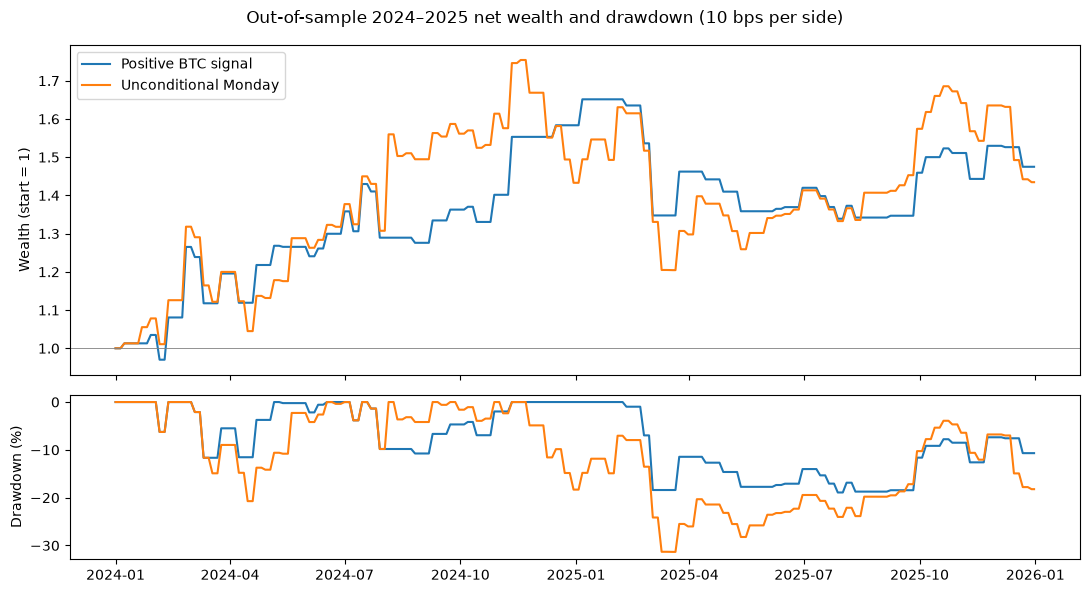

In [35]:
wealth_drawdown_plot({k[1]: v for k, v in all_dailies.items() if k[0] == "out_of_sample"},
                     f"Out-of-sample 2024–2025 net wealth and drawdown ({CONFIG['base_cost_bps_per_side']} bps per side)",
                     FIGURES / "oos_wealth_drawdown.png")

coef  se_hc3       p    n      r2
weekend   gap ~ btc   const       0.0014  0.0016  0.3775   91  0.8730
                      btc_return  1.0444  0.0527  0.0000   91  0.8730
          drift ~ btc const       0.0085  0.0063  0.1785   91  0.0418
                      btc_return -0.2983  0.3609  0.4085   91  0.0418
weeknight gap ~ btc   const       0.0000  0.0007  0.9488  384  0.7011
                      btc_return  1.1911  0.0494  0.0000  384  0.7011
          drift ~ btc const      -0.0028  0.0022  0.2037  384  0.0016
                      btc_return -0.0906  0.1214  0.4556  384  0.0016

,weekend,weeknight
n_pos,53.0000,212.0000
mean_drift_pos,0.0109,-0.0047
median_drift_pos,0.0056,-0.0027
n_nonpos,38.0000,172.0000
mean_drift_nonpos,0.0027,-0.0008
median_drift_nonpos,-0.0024,-0.0040
difference,0.0082,-0.0039
welch_t,0.7022,-0.8862
welch_p,0.4846,0.3761


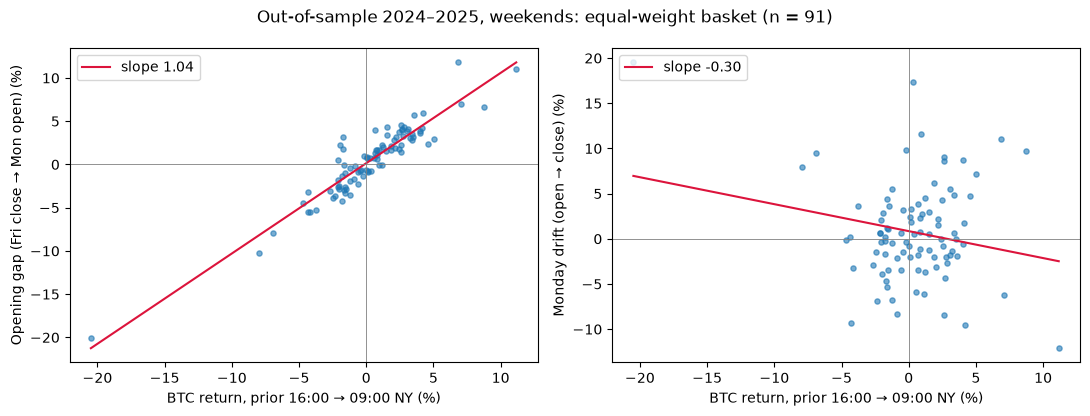

In [36]:
oos_wk = analysis_frame("out_of_sample", "weekend")
oos_wn = analysis_frame("out_of_sample", "weeknight")
reg_oos = pd.concat({
    ("weekend", "gap ~ btc"): ols(oos_wk, "basket_gap", ["btc_return"]),
    ("weekend", "drift ~ btc"): ols(oos_wk, "basket_drift", ["btc_return"]),
    ("weeknight", "gap ~ btc"): ols(oos_wn, "basket_gap", ["btc_return"]),
    ("weeknight", "drift ~ btc"): ols(oos_wn, "basket_drift", ["btc_return"]),
})
reg_oos.to_csv(RESULTS / "regressions_out_of_sample.csv")
reg_is.to_csv(RESULTS / "regressions_in_sample.csv")
display(reg_oos.round(4))
display(pd.DataFrame({"weekend": conditional_drift(oos_wk), "weeknight": conditional_drift(oos_wn)}).round(4))
scatter_panel(oos_wk, "Out-of-sample 2024–2025, weekends: equal-weight basket", FIGURES / "oos_weekend_scatter.png")

In [37]:
boot_oos = pd.concat({
    "weekend": bootstrap_event_stats(oos_wk, CONFIG["base_cost_bps_per_side"], CONFIG["bootstrap_reps"], CONFIG["seed"]),
    "weeknight": bootstrap_event_stats(oos_wn, CONFIG["base_cost_bps_per_side"], CONFIG["bootstrap_reps"], CONFIG["seed"]).iloc[:1],
})
boot_oos.to_csv(RESULTS / "bootstrap_out_of_sample.csv")
boot_oos.round(4)

n_events  estimate  ci_2.5%  ci_97.5%  share_of_draws_above_0
weekend   drift difference (BTC>0 minus BTC<=0)                     91    0.0082  -0.0162    0.0299                  0.7695
          excess return per event (strategy - benchmark, ...        91   -0.0003  -0.0081    0.0065                  0.4815
weeknight drift difference (BTC>0 minus BTC<=0)                    384   -0.0039  -0.0130    0.0046                  0.1960

In [38]:
cost_oos = pd.DataFrame([
    {"cost_bps_per_side": bps, "strategy": label, **compute_metrics(*run_portfolio(col, "out_of_sample", bps))}
    for bps in CONFIG["cost_scenarios_bps"] for label, col in STRATEGIES.items()
])
cost_oos.to_csv(RESULTS / "cost_sensitivity_out_of_sample.csv", index=False)
display(cost_oos.pivot(index="cost_bps_per_side", columns="strategy",
                       values=["cumulative_return", "sharpe_daily_zero_rf"]).round(4))

sens_oos, _, _ = results_table(["out_of_sample"], SENSITIVITIES, CONFIG["base_cost_bps_per_side"])
sens_oos.to_csv(RESULTS / "threshold_sensitivity_out_of_sample.csv", index=False)
sens_oos[["strategy", "trade_days", "exposure", "gross_cumulative_return", "cumulative_return",
          "sharpe_daily_zero_rf", "max_drawdown", "avg_trade_return", "win_rate"]].style.format(fmt)

cumulative_return                      sharpe_daily_zero_rf                     
strategy          Positive BTC signal Unconditional Monday  Positive BTC signal Unconditional Monday
cost_bps_per_side                                                                                   
0                              0.6398               0.7209               1.0007               0.9125
5                              0.5551               0.5712               0.9112               0.7912
10                             0.4749               0.4346               0.8208               0.6691
25                             0.2580               0.0918               0.5453               0.2994
50                            -0.0348              -0.3073               0.0757              -0.3230

,strategy,trade_days,exposure,gross_cumulative_return,cumulative_return,sharpe_daily_zero_rf,max_drawdown,avg_trade_return,win_rate
0,Threshold > 0 (primary),53,10.6%,64.0%,47.5%,0.82,-18.9%,0.88%,52.8%
1,Threshold > 1%,37,7.4%,22.7%,14.0%,0.40,-17.2%,0.50%,48.6%
2,Threshold > 2%,29,5.8%,21.9%,15.0%,0.43,-13.1%,0.65%,48.3%
3,Unconditional Monday,91,18.1%,72.1%,43.5%,0.67,-31.3%,0.54%,48.4%


In [39]:
per_year_oos = pd.DataFrame([
    {"year": y, "strategy": label,
     **compute_metrics(*run_portfolio(col, (f"{y}-01-01", f"{y}-12-31"), CONFIG["base_cost_bps_per_side"]))}
    for y in (2024, 2025) for label, col in STRATEGIES.items()
])
per_year_oos.to_csv(RESULTS / "per_year_out_of_sample.csv", index=False)
display(per_year_oos[["year", "strategy", "trade_days", "cumulative_return", "sharpe_daily_zero_rf",
                      "max_drawdown", "win_rate"]].style.format(fmt))

diag_oos = oos_wk.dropna(subset=["btc_session_return_hindsight"])
display(ols(diag_oos, "basket_drift", ["btc_return", "btc_session_return_hindsight"]).round(4))

conc_oos = pd.DataFrame({k[1]: concentration(v) for k, v in all_dailies.items() if k[0] == "out_of_sample"})
conc_oos.to_csv(RESULTS / "concentration_out_of_sample.csv")
conc_oos

,year,strategy,trade_days,cumulative_return,sharpe_daily_zero_rf,max_drawdown,win_rate
0,2024,Positive BTC signal,28,58.3%,1.52,-11.7%,60.7%
1,2024,Unconditional Monday,46,43.3%,1.04,-20.7%,50.0%
2,2025,Positive BTC signal,25,-6.9%,-0.21,-18.9%,44.0%
3,2025,Unconditional Monday,45,0.1%,0.15,-26.1%,46.7%


,coef,se_hc3,p,n,r2
const,0.0017,0.0034,0.6070,91,0.6421
btc_return,-0.0979,0.1518,0.5188,91,0.6421
btc_session_return_hindsight,1.7421,0.1573,0.0000,91,0.6421


,Positive BTC signal,Unconditional Monday
trade_days,53,91
cumulative_return,0.474853,0.434553
without_best_5,-0.143255,-0.240478
without_worst_5,1.322788,1.393516
best_day,0.170779,0.192946
best_day_date,2024-02-26,2024-08-05
worst_day,-0.122826,-0.122826
worst_day_date,2025-03-03,2025-03-03


# 9. Post-freeze robustness

Analyses added on 2026-10-08, **after** the out-of-sample results had been seen. They do not change the primary rule and are not untouched out-of-sample validation; they help interpret the results already obtained.

### 9.1 Random-selection benchmark

The signal trades fewer Mondays than the unconditional benchmark, so part of any difference is just lower exposure and lower costs. Here the same number of eligible Mondays as the signal traded is drawn at random 10,000 times (same costs, fills and daily compounding). The question: where does the Bitcoin-timed selection rank among equally sized random selections?

In [40]:
def random_selection_benchmark(period, signal_col="signal_long", cost_bps=CONFIG["base_cost_bps_per_side"],
                               reps=10_000, seed=CONFIG["seed"]):
    start, end = CONFIG["periods"][period]
    c = cost_bps / 1e4
    ev = (outcomes.merge(signals[["event_id", signal_col]], on="event_id")
          .query("event_type == 'weekend' and eligible and period == @period"))
    net = ((1 + ev["basket_drift"]) * (1 - c) / (1 + c) - 1).to_numpy()  # net basket return if traded
    chosen = ev[signal_col].to_numpy()
    k, n = int(chosen.sum()), len(net)
    n_sessions = int(calendar["session"].between(start, end).sum())

    def stats(r):
        # r holds the trade returns; every other session is cash (0), so sums over r are sums over all days.
        cum = np.expm1(np.log1p(r).sum(axis=-1))
        mean = r.sum(axis=-1) / n_sessions
        sd = np.sqrt(((r ** 2).sum(axis=-1) - n_sessions * mean ** 2) / (n_sessions - 1))
        return cum, np.sqrt(252) * mean / sd

    sig_cum, sig_sharpe = stats(net[chosen])
    ref = main_table.set_index(["period", "strategy"]).loc[(period, "Positive BTC signal")]
    assert np.isclose(sig_cum, ref["cumulative_return"]) and np.isclose(sig_sharpe, ref["sharpe_daily_zero_rf"])

    rng = np.random.default_rng(seed)
    idx = np.argsort(rng.random((reps, n)), axis=1)[:, :k]  # each row: k distinct random eligible Mondays
    rand_cum, rand_sharpe = stats(net[idx])
    summary = {
        "period": period, "eligible_mondays": n, "trades_per_draw": k, "draws": reps,
        "signal_cumulative_return": sig_cum, "random_median_cumulative_return": np.median(rand_cum),
        "random_5%": np.percentile(rand_cum, 5), "random_95%": np.percentile(rand_cum, 95),
        "share_random_below_signal": (rand_cum < sig_cum).mean(),
        "signal_sharpe": sig_sharpe, "random_median_sharpe": np.median(rand_sharpe),
        "share_random_sharpe_below_signal": (rand_sharpe < sig_sharpe).mean(),
    }
    return summary, rand_cum


rs_results = {p: random_selection_benchmark(p) for p in ["in_sample", "out_of_sample"]}
random_sel = pd.DataFrame([s for s, _ in rs_results.values()]).set_index("period")
random_sel.to_csv(RESULTS / "random_selection_benchmark.csv")
random_sel.T

period,in_sample,out_of_sample
eligible_mondays,128.000000,91.000000
trades_per_draw,60.000000,53.000000
draws,10000.000000,10000.000000
signal_cumulative_return,-0.188270,0.474853
random_median_cumulative_return,-0.099930,0.242696
random_5%,-0.442983,-0.187020
random_95%,0.468525,0.850995
share_random_below_signal,0.365400,0.761000
signal_sharpe,-0.162261,0.820795
random_median_sharpe,-0.034201,0.524860


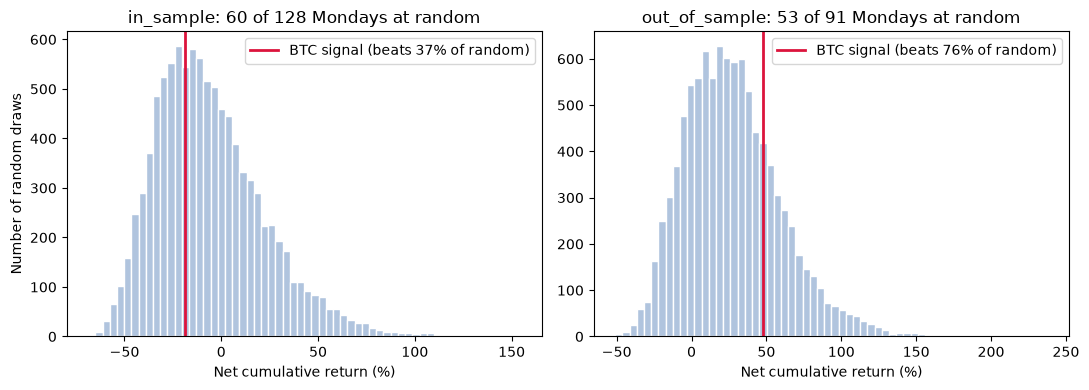

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (period, (summary, rand_cum)) in zip(axes, rs_results.items()):
    ax.hist(rand_cum * 100, bins=60, color="lightsteelblue", edgecolor="white")
    ax.axvline(summary["signal_cumulative_return"] * 100, color="crimson", lw=2,
               label=f"BTC signal (beats {summary['share_random_below_signal']:.0%} of random)")
    ax.set_title(f"{period}: {summary['trades_per_draw']} of {summary['eligible_mondays']} Mondays at random")
    ax.set_xlabel("Net cumulative return (%)"); ax.legend(loc="upper right")
axes[0].set_ylabel("Number of random draws")
fig.tight_layout(); fig.savefig(FIGURES / "random_selection_benchmark.png", dpi=150); plt.show()

### 9.2 Are consecutive events independent? (simple check)

The bootstrap intervals assume each event is independent of the previous one. A simple check: the correlation between each event's basket drift and the previous event's (lag-1 autocorrelation). With n events, values inside roughly ±2/√n are indistinguishable from zero. 

In [42]:
dep_rows = []
for period in ["in_sample", "out_of_sample"]:
    for etype in ["weekend", "weeknight"]:
        df = analysis_frame(period, etype)  # already in date order
        dep_rows.append({"period": period, "events": etype, "n": len(df),
                         "drift_autocorr_lag1": df["basket_drift"].autocorr(lag=1),
                         "noise_band_plus_minus": 2 / np.sqrt(len(df))})
dependence = pd.DataFrame(dep_rows)
dependence["inside_noise_band"] = dependence["drift_autocorr_lag1"].abs() < dependence["noise_band_plus_minus"]
dependence.to_csv(RESULTS / "serial_dependence_lag1.csv", index=False)
dependence.round(3)

,period,events,n,drift_autocorr_lag1,noise_band_plus_minus,inside_noise_band
0,in_sample,weekend,128,0.005,0.177,True
1,in_sample,weeknight,592,-0.006,0.082,True
2,out_of_sample,weekend,91,-0.036,0.210,True
3,out_of_sample,weeknight,384,-0.078,0.102,True
